In [1]:
import pandas as pd

df = pd.read_excel("titanic-2024-02-08.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), object(1), str(4)
memory usage: 113.0+ KB

First 5 Records:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print("Missing Values:")
print(df.isnull().sum())

print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Missing Value Percentage:
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

Duplicate Rows: 0

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [4]:
eda_df = df.copy()

eda_df["Age"] = eda_df["Age"].fillna(eda_df["Age"].median())

eda_df["Embarked"] = eda_df["Embarked"].fillna(
    eda_df["Embarked"].mode()[0]
)

print("Missing values after preparation:")
print(eda_df.isnull().sum())

print("\nDataset Shape:", eda_df.shape)

Missing values after preparation:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

Dataset Shape: (891, 12)


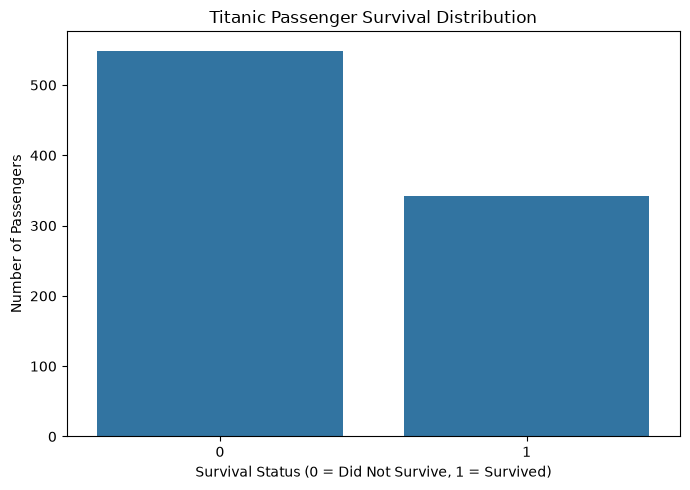

Survival Counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=eda_df, x="Survived")

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

print("Survival Counts:")
print(eda_df["Survived"].value_counts().sort_index())

print("\nSurvival Percentages:")
print(
    (eda_df["Survived"].value_counts(normalize=True) * 100)
    .sort_index()
    .round(2)
)

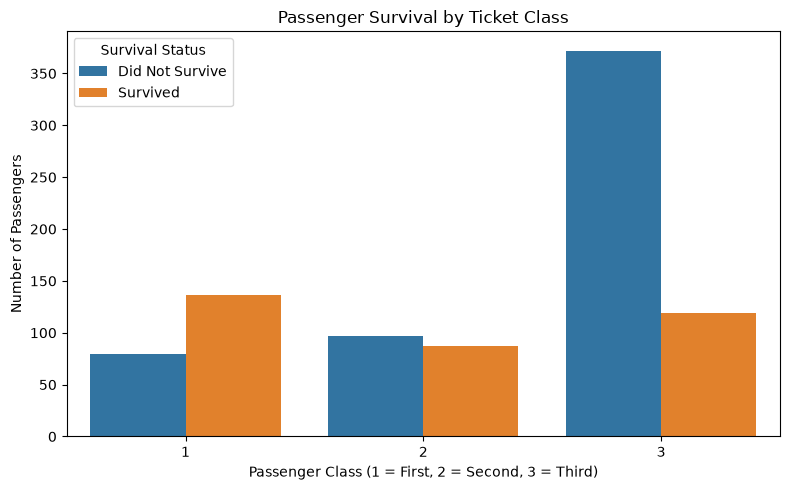

Survival Percentage by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=eda_df,
    x="Pclass",
    hue="Survived"
)

plt.title("Passenger Survival by Ticket Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Survival Status",
    labels=["Did Not Survive", "Survived"]
)

plt.tight_layout()
plt.show()

class_survival = (
    eda_df.groupby("Pclass")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

print("Survival Percentage by Passenger Class:")
print(class_survival)

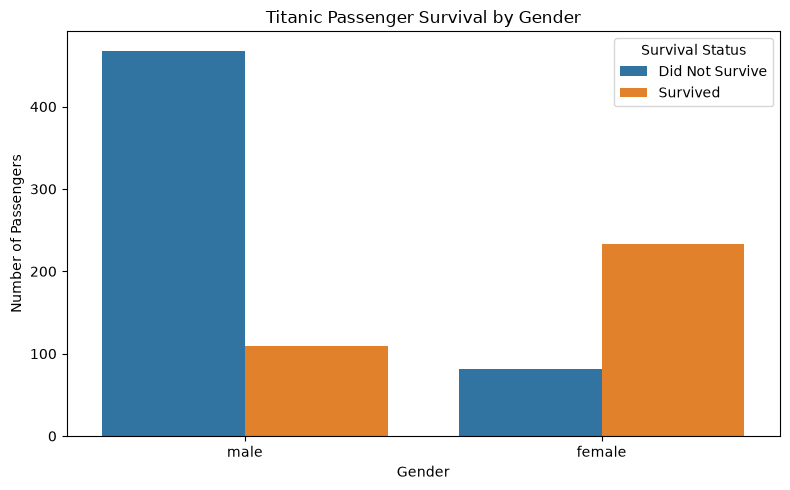

Survival Percentage by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(
    data=eda_df,
    x="Sex",
    hue="Survived"
)

plt.title("Titanic Passenger Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.legend(
    title="Survival Status",
    labels=["Did Not Survive", "Survived"]
)

plt.tight_layout()
plt.show()

gender_survival = (
    eda_df.groupby("Sex")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

print("Survival Percentage by Gender:")
print(gender_survival)

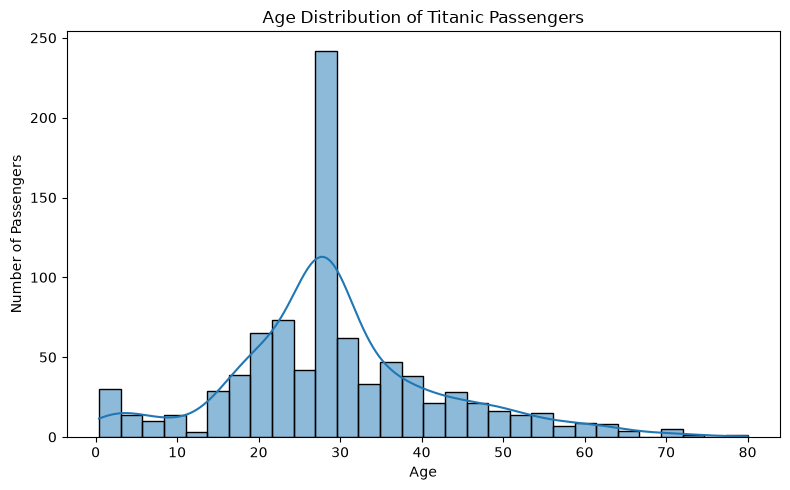

Passenger Age Statistics:
count    891.00
mean      29.36
std       13.02
min        0.42
25%       22.00
50%       28.00
75%       35.00
max       80.00
Name: Age, dtype: float64


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=eda_df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

print("Passenger Age Statistics:")
print(eda_df["Age"].describe().round(2))

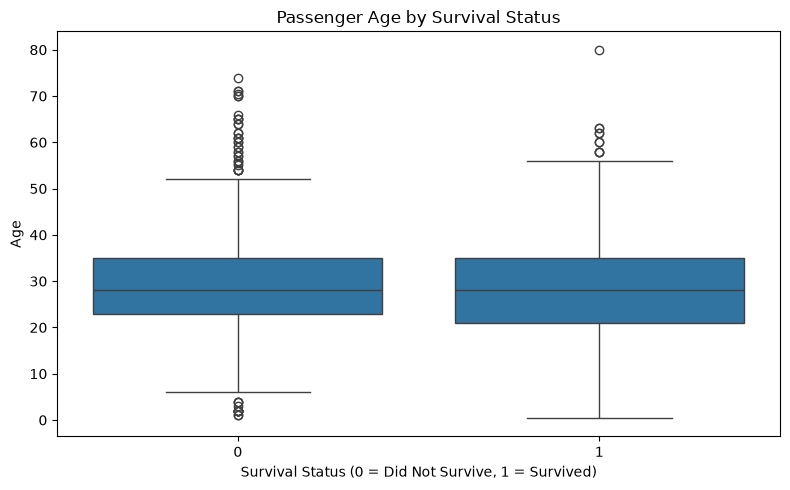

Average Age by Survival Status:
Survived
0    30.03
1    28.29
Name: Age, dtype: float64

Median Age by Survival Status:
Survived
0    28.0
1    28.0
Name: Age, dtype: float64


In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="Survived",
    y="Age"
)

plt.title("Passenger Age by Survival Status")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

print("Average Age by Survival Status:")
print(eda_df.groupby("Survived")["Age"].mean().round(2))

print("\nMedian Age by Survival Status:")
print(eda_df.groupby("Survived")["Age"].median().round(2))

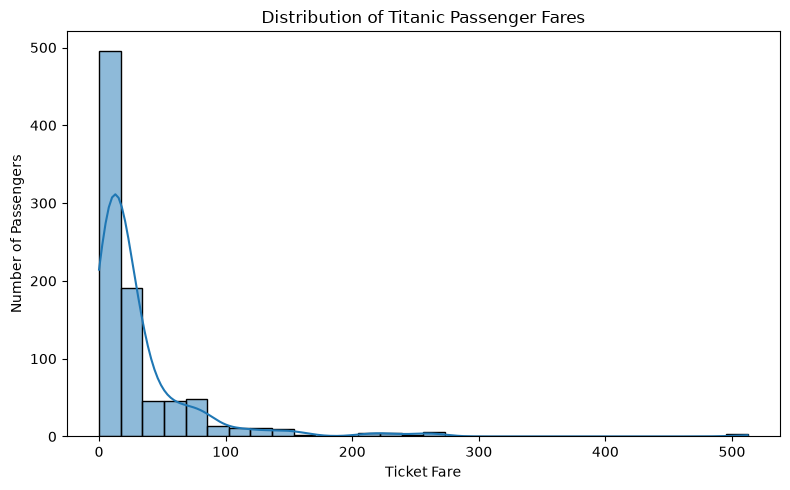

Passenger Fare Statistics:
count    891.00
mean      32.20
std       49.69
min        0.00
25%        7.91
50%       14.45
75%       31.00
max      512.33
Name: Fare, dtype: float64


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=eda_df,
    x="Fare",
    bins=30,
    kde=True
)

plt.title("Distribution of Titanic Passenger Fares")
plt.xlabel("Ticket Fare")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

print("Passenger Fare Statistics:")
print(eda_df["Fare"].describe().round(2))

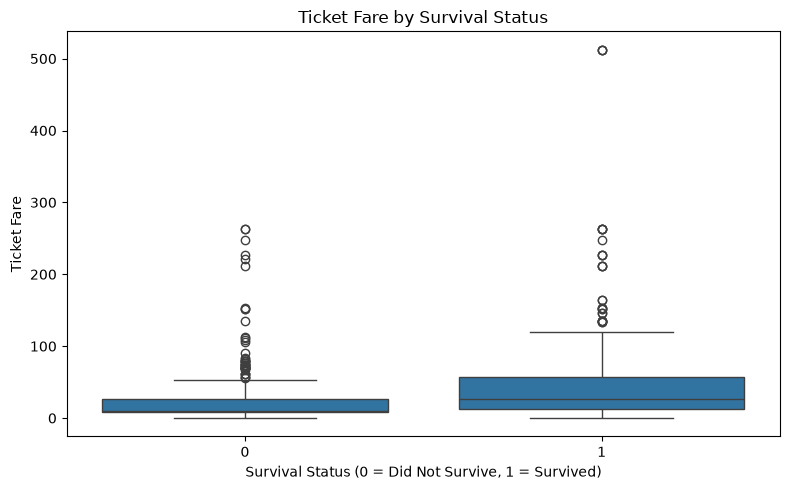

Average Fare by Survival Status:
Survived
0    22.12
1    48.40
Name: Fare, dtype: float64

Median Fare by Survival Status:
Survived
0    10.5
1    26.0
Name: Fare, dtype: float64


In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x="Survived",
    y="Fare"
)

plt.title("Ticket Fare by Survival Status")
plt.xlabel("Survival Status (0 = Did Not Survive, 1 = Survived)")
plt.ylabel("Ticket Fare")

plt.tight_layout()
plt.show()

print("Average Fare by Survival Status:")
print(eda_df.groupby("Survived")["Fare"].mean().round(2))

print("\nMedian Fare by Survival Status:")
print(eda_df.groupby("Survived")["Fare"].median().round(2))

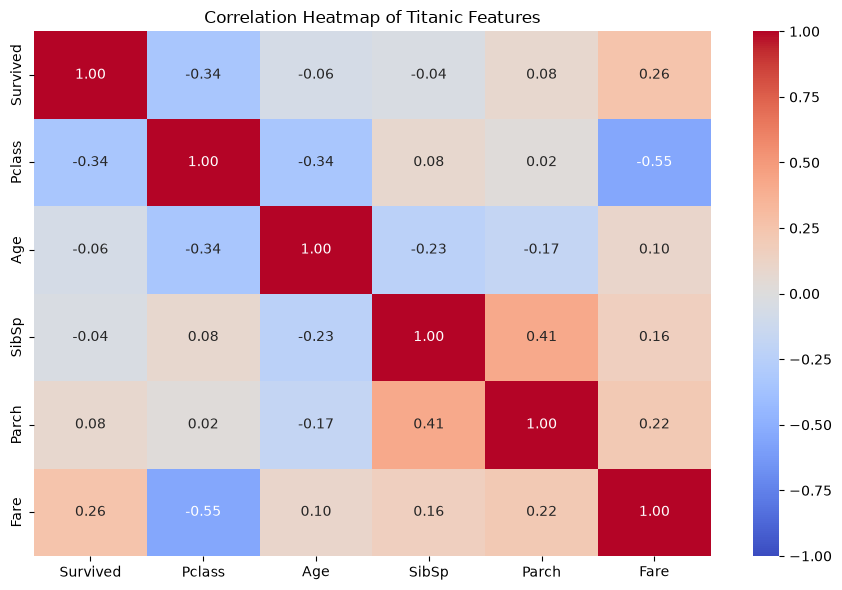

In [12]:
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]

corr = eda_df[numeric_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Titanic Features")
plt.tight_layout()
plt.show()

Survival Percentage by Embarkation Port:
Embarked
C    55.36
Q    38.96
S    33.90
Name: Survived, dtype: float64


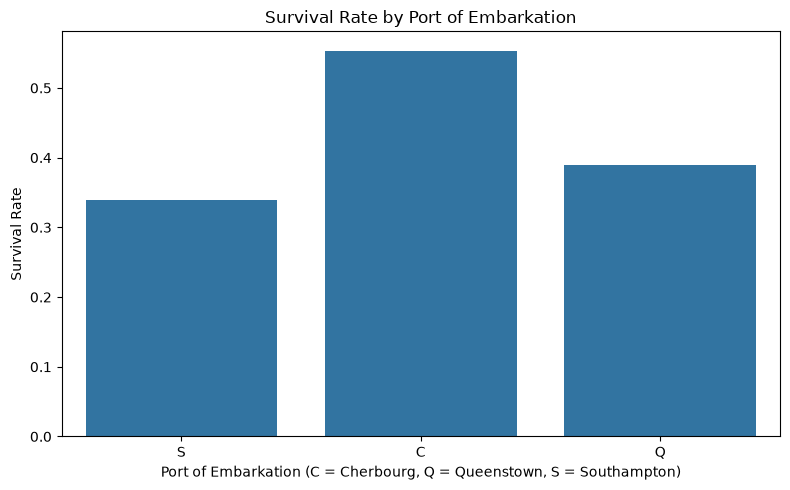

In [13]:
embarked_survival = (
    eda_df.groupby("Embarked")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

print("Survival Percentage by Embarkation Port:")
print(embarked_survival)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=eda_df,
    x="Embarked",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Port of Embarkation")
plt.xlabel("Port of Embarkation (C = Cherbourg, Q = Queenstown, S = Southampton)")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

Survival Percentage by Passenger Class and Gender:
Pclass  Sex   
1       female    96.81
        male      36.89
2       female    92.11
        male      15.74
3       female    50.00
        male      13.54
Name: Survived, dtype: float64


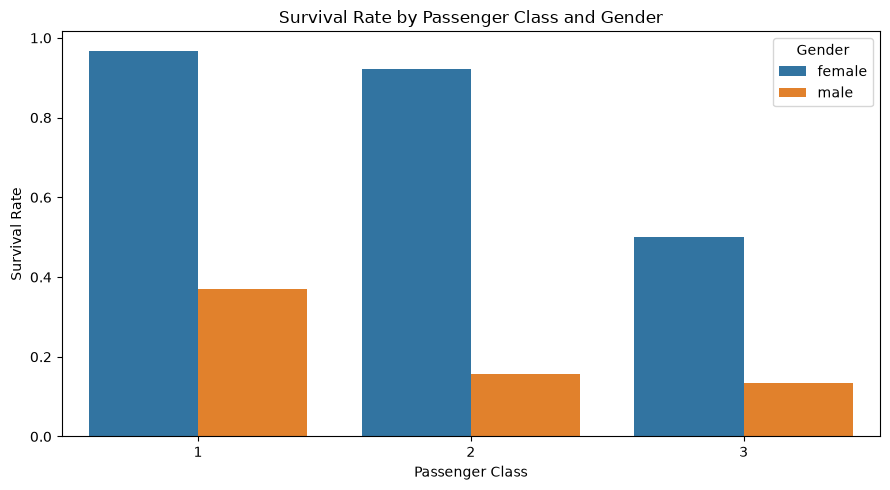

In [14]:
gender_class_survival = (
    eda_df.groupby(["Pclass", "Sex"])["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

print("Survival Percentage by Passenger Class and Gender:")
print(gender_class_survival)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=eda_df,
    x="Pclass",
    y="Survived",
    hue="Sex",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class and Gender")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

Family Size Distribution:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

Survival Percentage by Family Size:
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64


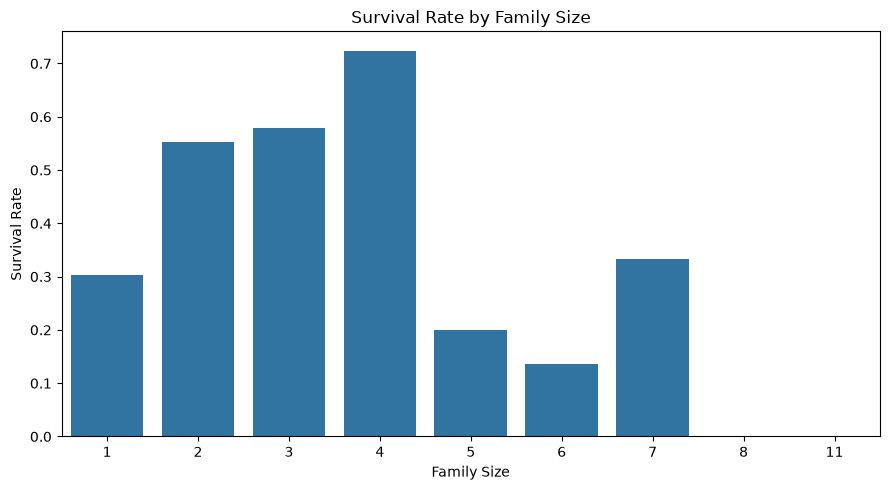

In [15]:
eda_df["FamilySize"] = eda_df["SibSp"] + eda_df["Parch"] + 1

print("Family Size Distribution:")
print(eda_df["FamilySize"].value_counts().sort_index())

family_survival = (
    eda_df.groupby("FamilySize")["Survived"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nSurvival Percentage by Family Size:")
print(family_survival)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=eda_df,
    x="FamilySize",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size")
plt.ylabel("Survival Rate")
plt.tight_layout()
plt.show()

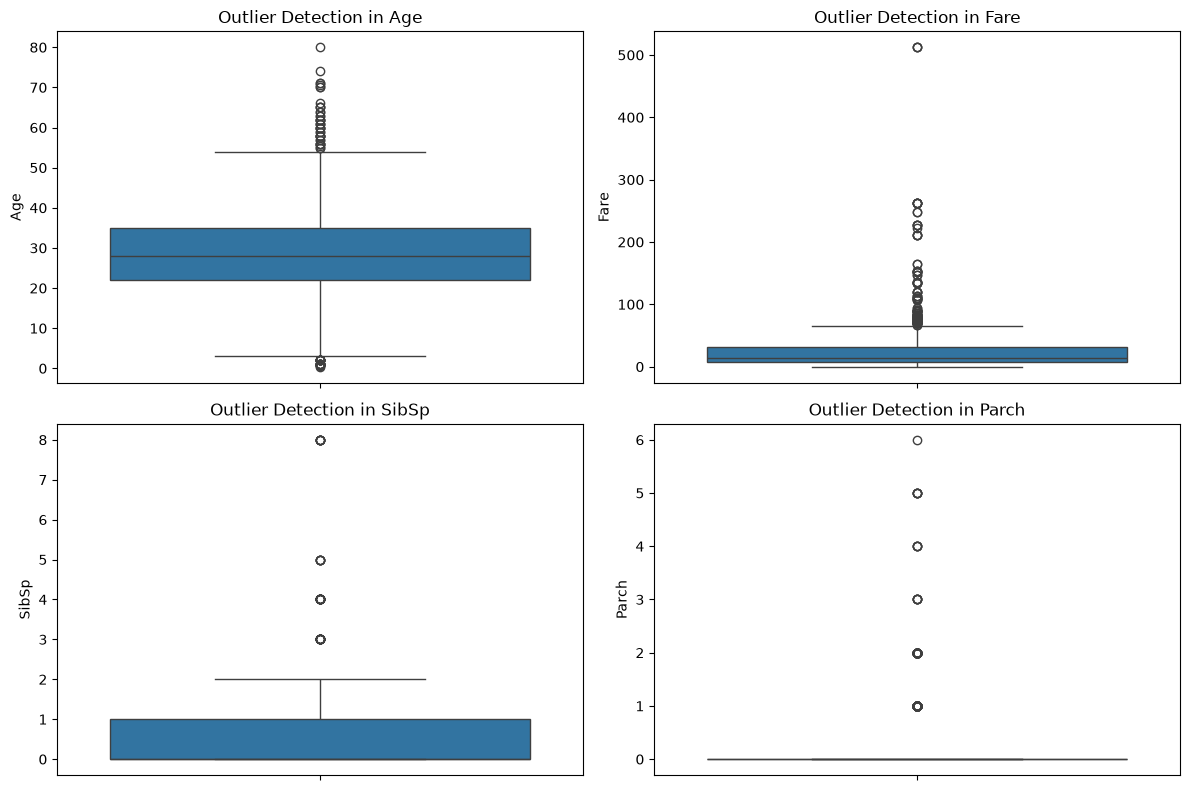

In [16]:

numeric_columns = ["Age", "Fare", "SibSp", "Parch"]

plt.figure(figsize=(12, 8))

for i, column in enumerate(numeric_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(data=eda_df, y=column)
    plt.title(f"Outlier Detection in {column}")

plt.tight_layout()
plt.show()

In [17]:

print("========== TITANIC EDA: KEY FINDINGS ==========\n")

# 1. Overall survival
survival_rate = eda_df["Survived"].mean() * 100
print(f"1. Overall Survival Rate: {survival_rate:.2f}%")

gender_rate = (
    eda_df.groupby("Sex")["Survived"].mean() * 100
).round(2)
print("\n2. Survival Rate by Gender:")
print(gender_rate)

class_rate = (
    eda_df.groupby("Pclass")["Survived"].mean() * 100
).round(2)
print("\n3. Survival Rate by Passenger Class:")
print(class_rate)

port_rate = (
    eda_df.groupby("Embarked")["Survived"].mean() * 100
).round(2)
print("\n4. Survival Rate by Embarkation Port:")
print(port_rate)

family_rate = (
    eda_df.groupby("FamilySize")["Survived"].mean() * 100
).round(2)
print("\n5. Survival Rate by Family Size:")
print(family_rate)

print("\n6. Missing Values After Preparation:")
print(eda_df.isnull().sum())

print("\n========== EDA SUMMARY COMPLETED ==========")

========== TITANIC EDA: KEY FINDINGS ==========

1. Overall Survival Rate: 38.38%

2. Survival Rate by Gender:
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

3. Survival Rate by Passenger Class:
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

4. Survival Rate by Embarkation Port:
Embarked
C    55.36
Q    38.96
S    33.90
Name: Survived, dtype: float64

5. Survival Rate by Family Size:
FamilySize
1     30.35
2     55.28
3     57.84
4     72.41
5     20.00
6     13.64
7     33.33
8      0.00
11     0.00
Name: Survived, dtype: float64

6. Missing Values After Preparation:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
FamilySize       0
dtype: int64

========== EDA SUMMARY COMPLETED ==========
